In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [15]:
df = pd.read_csv("uber.csv")

print(df.shape)
df.head()

(200000, 9)


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [16]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [17]:
df = df.dropna()
df = df.drop_duplicates()

In [18]:
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["pickup_datetime"].dt.hour

In [19]:
df = df.drop(["key", "pickup_datetime"], axis = 1)

In [22]:
print("dataset after pre-processing:")
print(df.shape)
df.head()

dataset after pre-processing:
(199999, 8)


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour
0,24238194,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19
1,27835199,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20
2,44984355,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21
3,25894730,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8
4,17610152,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17


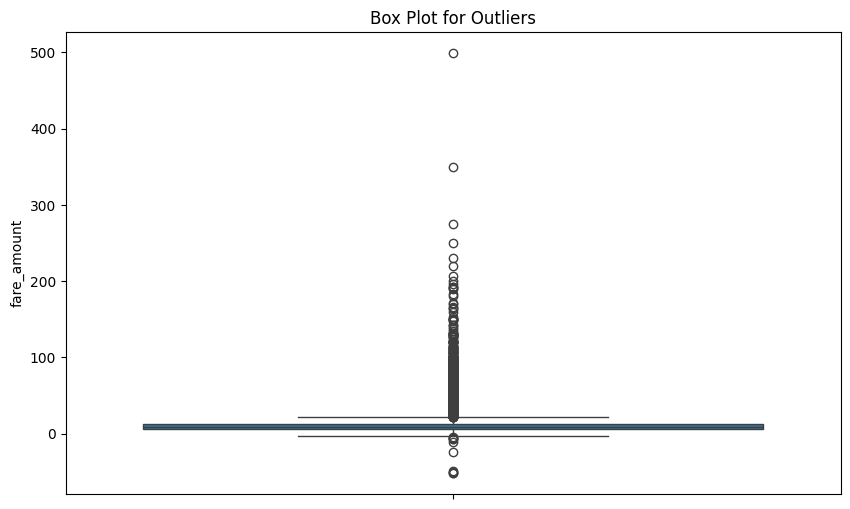

In [33]:
plt.figure(figsize=(10,6))
sns.boxplot(y = df["fare_amount"])
plt.title("Box Plot for Outliers")
plt.show()

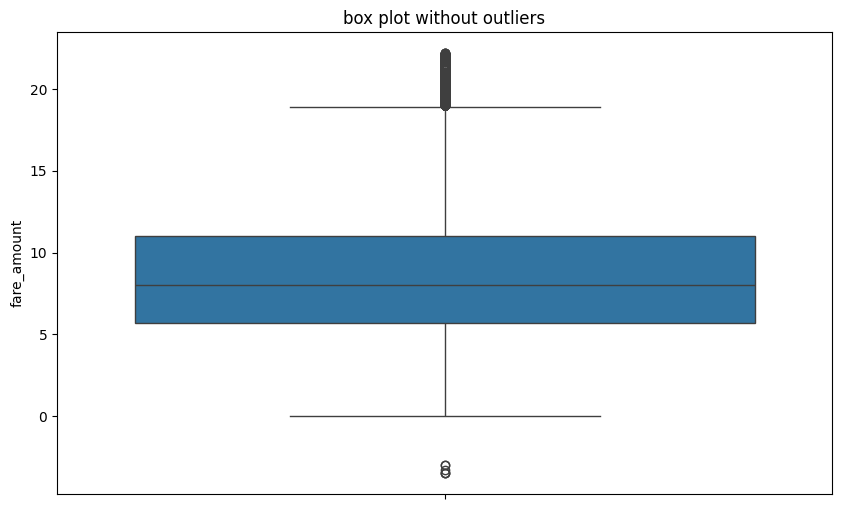

In [34]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

df = df[
    (df["fare_amount"] >= Q1 - IQR * 1.5) &
    (df["fare_amount"] <= Q3 + IQR * 1.5)
]

plt.figure(figsize=(10, 6))
sns.boxplot(y = df["fare_amount"])
plt.title("box plot without outliers")
plt.show()

In [35]:
print(df.shape)
df.head()

(182833, 8)


,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour
0,24238194,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19
1,27835199,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20
2,44984355,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21
3,25894730,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8
4,17610152,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17


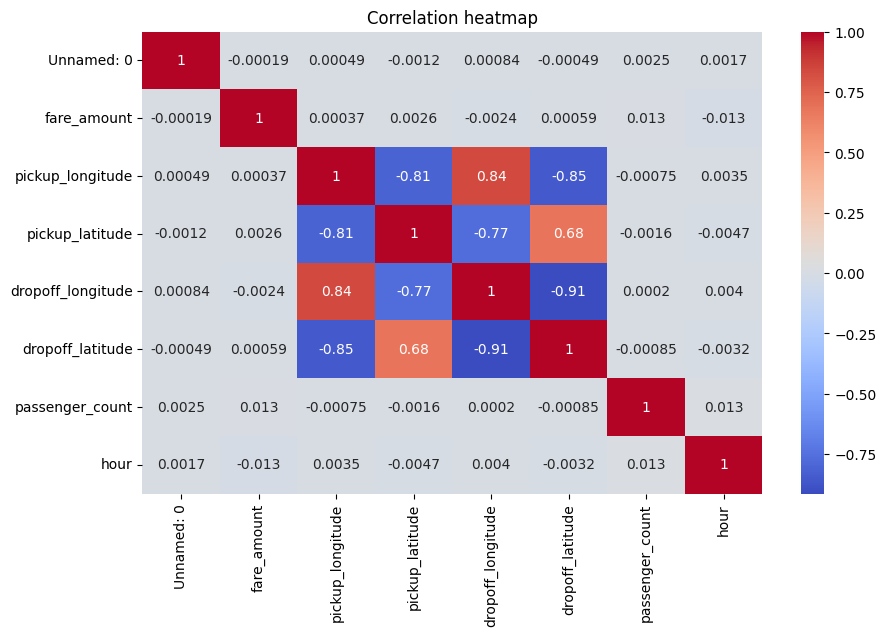

In [36]:
correlation = df.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot = True, cmap = "coolwarm")
plt.title("Correlation heatmap")
plt.show()

In [37]:
X = df.drop("fare_amount", axis = 1)
y = df["fare_amount"]

In [38]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42
)

In [46]:
lr = LinearRegression()

lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

In [48]:
rf = RandomForestRegressor(
    n_estimators = 50, random_state = 42
)

rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [50]:
lr_r2 = r2_score(y_test, lr_pred)
lr_rmse = mean_squared_error(y_test, lr_pred)**0.5

rf_r2 = r2_score(y_test, rf_pred)
rf_rmse = mean_squared_error(y_test, rf_pred)**0.5

print("Compare Models:\n")

print("results of Linear Regression:\n")
print("R2 score:", lr_r2)
print("RMSE:", lr_rmse)

print("results of Random Forest Regression:\n")
print("R2 score:", rf_r2)
print("RMSE:", rf_rmse)

Compare Models:

results of Linear Regression:

R2 score: 0.00012949157728081584
RMSE: 4.136528060006628
results of Random Forest Regression:

R2 score: 0.7113695886810796
RMSE: 2.2224660699741623
